# T27: non-rotator negatives from SMARTS noise stacks

Regenerates every figure in `README.md` from saved data: `data/` (committed) and
`runs/t27_ranker/` (gitignored; `python tools/train_ranker_negatives.py ...` rebuilds it).

In [1]:
import json, os, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
HERE = Path.cwd()
ROOT = HERE if (HERE / 'claude_files').exists() else HERE.parents[1]
sys.path.insert(0, str(ROOT / 'claude_files'))
import evaluation as ev
D = ROOT / 'reports/2026-11-10_t27-nonrotator-negatives' / 'data'
F = ROOT / 'reports/2026-11-10_t27-nonrotator-negatives' / 'figures'
RUN = ROOT / 'runs' / 't27_ranker'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
COV = ['single','consecutive-2','gapped-2','consecutive-3-5','gapped-3-5','consecutive-6-12','gapped-6-12','full','fullyear']
C = dict(neg='#c62828', rot='#1565c0', succ='#2e7d32', wrong='#ef6c00', grey='#757575')

## 1. Is a stack a fair non-rotator?
Left: mean fraction of stacking members whose injected PERIOD is within 2% of the stack's LS top period, vs a permutation null (P1 from another source). Right: white-noise (point-to-point) scatter of the stack vs its single member files.

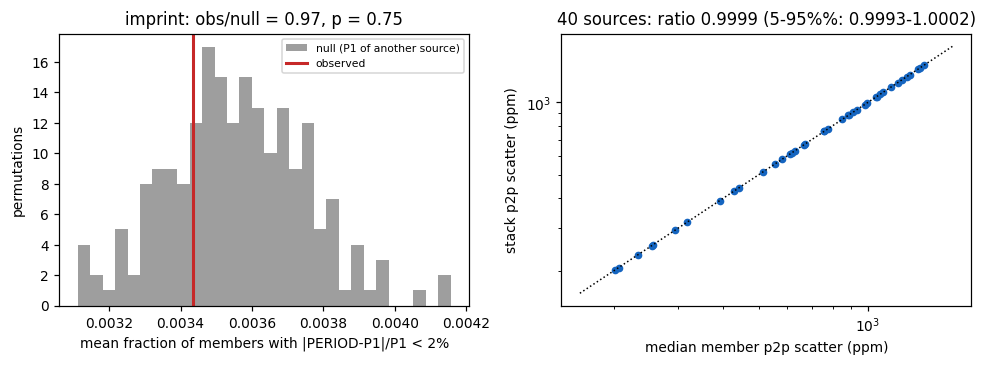

In [2]:
fs = pd.read_csv(D / 'fairness_sources.csv'); fz = json.load(open(D / 'fairness_summary.json'))
null = np.load(D / 'fairness_imprint_null.npy')
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].hist(null, 30, color=C['grey'], alpha=.7, label='null (P1 of another source)')
ax[0].axvline(fz['imprint_mean_match_frac'], color=C['neg'], lw=2, label='observed')
ax[0].set_xlabel('mean fraction of members with |PERIOD-P1|/P1 < 2%'); ax[0].set_ylabel('permutations')
ax[0].set_title(f"imprint: obs/null = {fz['imprint_obs_over_null']:.2f}, p = {fz['imprint_perm_p_value']:.2f}"); ax[0].legend(fontsize=7)
m = fs.member_p2p_ppm_median.notna()
ax[1].loglog(fs.member_p2p_ppm_median[m], fs.stack_p2p_ppm[m], 'o', ms=4, color=C['rot'])
lim = [fs.stack_p2p_ppm[m].min()*0.8, fs.stack_p2p_ppm[m].max()*1.2]; ax[1].plot(lim, lim, 'k:', lw=1)
ax[1].set_xlabel('median member p2p scatter (ppm)'); ax[1].set_ylabel('stack p2p scatter (ppm)')
ax[1].set_title(f"{m.sum()} sources: ratio {fz['p2p_ratio_median']:.4f} (5-95%%: {fz['p2p_ratio_p05']:.4f}-{fz['p2p_ratio_p95']:.4f})")
fig.tight_layout(); fig.savefig(F / 'fairness.png', dpi=130); plt.show()

## 2. Hand arbitration's false positives
FP rate (any period reported) per coverage class, with Wilson 95% intervals; diamonds are the rotators' answer rate on dev_medium in the same class.

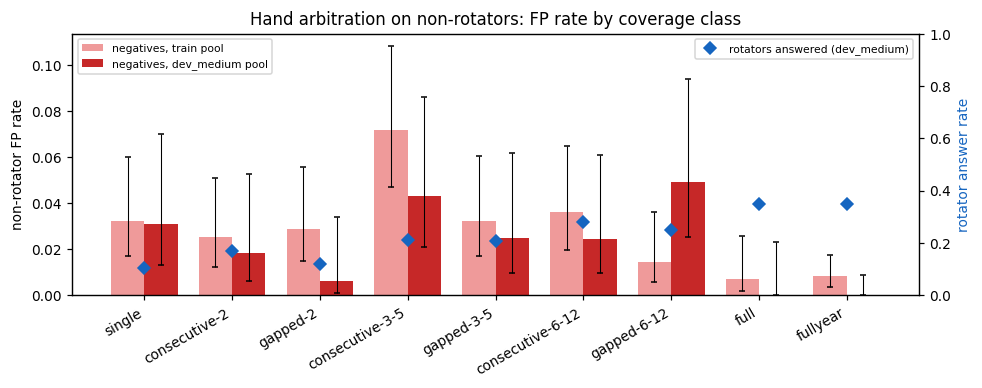

,eval_set,cov,n,n_answered,fp_rate,lo,hi,rot_answer_rate,rot_success_rate
0,dev_medium,single,163,5,0.030675,1.317200e-02,0.069791,0.104839,0.064516
1,dev_medium,consecutive-2,163,3,0.018405,6.278637e-03,0.052709,0.168000,0.080000
2,dev_medium,gapped-2,162,1,0.006173,1.090462e-03,0.034134,0.119048,0.079365
3,dev_medium,consecutive-3-5,163,7,0.042945,2.095545e-02,0.085982,0.212598,0.157480
4,dev_medium,gapped-3-5,162,4,0.024691,9.642777e-03,0.061760,0.208000,0.160000
5,dev_medium,consecutive-6-12,164,4,0.024390,9.524684e-03,0.061028,0.280000,0.240000
6,dev_medium,gapped-6-12,163,8,0.049080,2.507609e-02,0.093849,0.250000,0.137097
7,dev_medium,full,162,0,0.000000,-1.734723e-18,0.023164,0.346774,0.266129
8,dev_medium,fullyear,434,0,0.000000,0.000000e+00,0.008774,0.350000,0.248000
9,train,single,279,9,0.032258,1.706198e-02,0.060160,0.104839,0.064516


In [3]:
ct = pd.read_csv(D / 'fp_by_coverage.csv')
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(COV)); w = .38
for k, (s, col) in enumerate([('train', '#ef9a9a'), ('dev_medium', C['neg'])]):
    g = ct[ct.eval_set == s].set_index('cov').reindex(COV)
    ax.bar(x + (k - .5) * w, g.fp_rate, w, color=col, label=f'negatives, {s} pool',
           yerr=[g.fp_rate - g.lo, g.hi - g.fp_rate], capsize=2, error_kw=dict(lw=.7))
r = ct[ct.eval_set == 'dev_medium'].set_index('cov').reindex(COV)
ax2 = ax.twinx(); ax2.plot(x, r.rot_answer_rate, 'D', color=C['rot'], label='rotators answered (dev_medium)')
ax2.set_ylabel('rotator answer rate', color=C['rot']); ax2.set_ylim(0, 1)
ax.set_xticks(x); ax.set_xticklabels(COV, rotation=30, ha='right'); ax.set_ylabel('non-rotator FP rate')
ax.legend(loc='upper left', fontsize=7); ax2.legend(loc='upper right', fontsize=7)
ax.set_title('Hand arbitration on non-rotators: FP rate by coverage class')
fig.tight_layout(); fig.savefig(F / 'fp_by_coverage.png', dpi=130); plt.show()
ct

Reported periods of the FPs (all negatives, both pools) vs the rotators' answers on dev_medium (assigned coverage).

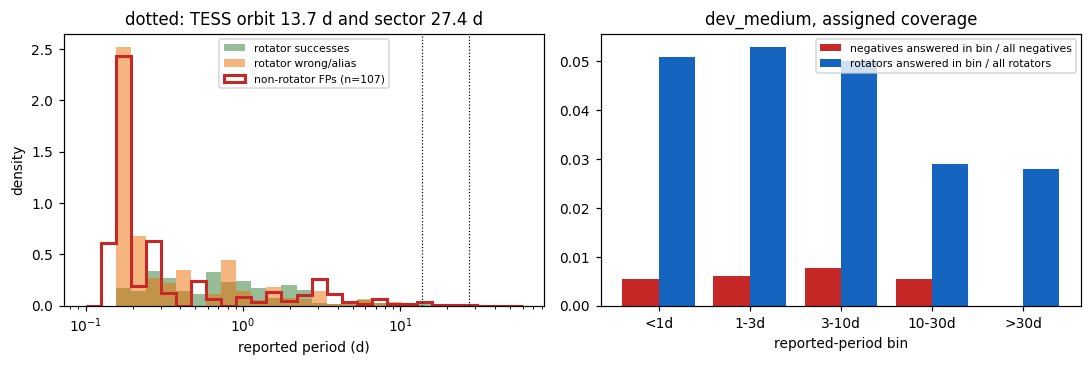

,kind,reported_bin,neg_fp,neg_n,neg_fp_rate,rot_answers,rot_n,rot_success,rot_wrong,precision_rot_only,precision_1to1
0,assigned,<1d,7,1302,0.005376,51,1000,31,20,0.607843,0.549876
1,assigned,1-3d,8,1302,0.006144,53,1000,40,13,0.754717,0.676311
2,assigned,3-10d,10,1302,0.007680,50,1000,33,17,0.660000,0.572117
3,assigned,10-30d,7,1302,0.005376,29,1000,25,4,0.862069,0.727244
4,assigned,>30d,0,1302,0.000000,28,1000,19,9,0.678571,0.678571


In [4]:
import glob
neg = pd.concat([pd.read_csv(p) for p in sorted((D).glob('neg_stars_*.csv.gz'))])
rot = pd.read_csv(D / 'rot_dev_assigned_answers.csv')
bins = np.geomspace(0.1, 60, 30)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
fp = neg[neg.final_outcome != 'none']
ax[0].hist(rot.final_period[rot.success], bins, color=C['succ'], alpha=.5, density=True, label='rotator successes')
ax[0].hist(rot.final_period[~rot.success], bins, color=C['wrong'], alpha=.5, density=True, label='rotator wrong/alias')
ax[0].hist(fp.final_period, bins, histtype='step', lw=2, color=C['neg'], density=True, label=f'non-rotator FPs (n={len(fp)})')
for p in (13.7, 27.4): ax[0].axvline(p, color='k', ls=':', lw=.8)
ax[0].set_xscale('log'); ax[0].set_xlabel('reported period (d)'); ax[0].set_ylabel('density'); ax[0].legend(fontsize=7)
ax[0].set_title('dotted: TESS orbit 13.7 d and sector 27.4 d')
pb = pd.read_csv(D / 'fp_by_period_bin.csv'); pb = pb[pb.kind == 'assigned']
xx = np.arange(len(pb))
ax[1].bar(xx - .2, pb.neg_fp_rate, .4, color=C['neg'], label='negatives answered in bin / all negatives')
ax[1].bar(xx + .2, pb.rot_answers / pb.rot_n, .4, color=C['rot'], label='rotators answered in bin / all rotators')
ax[1].set_xticks(xx); ax[1].set_xticklabels(pb.reported_bin); ax[1].set_xlabel('reported-period bin'); ax[1].legend(fontsize=7)
ax[1].set_title('dev_medium, assigned coverage')
fig.tight_layout(); fig.savefig(F / 'fp_by_period.png', dpi=130); plt.show()
pb

Examples: non-rotators (dev_medium pool) where the pipeline reported a period. Light curve, ACF and LS periodogram, reported P marked in red (and 2P, P/2 dotted).

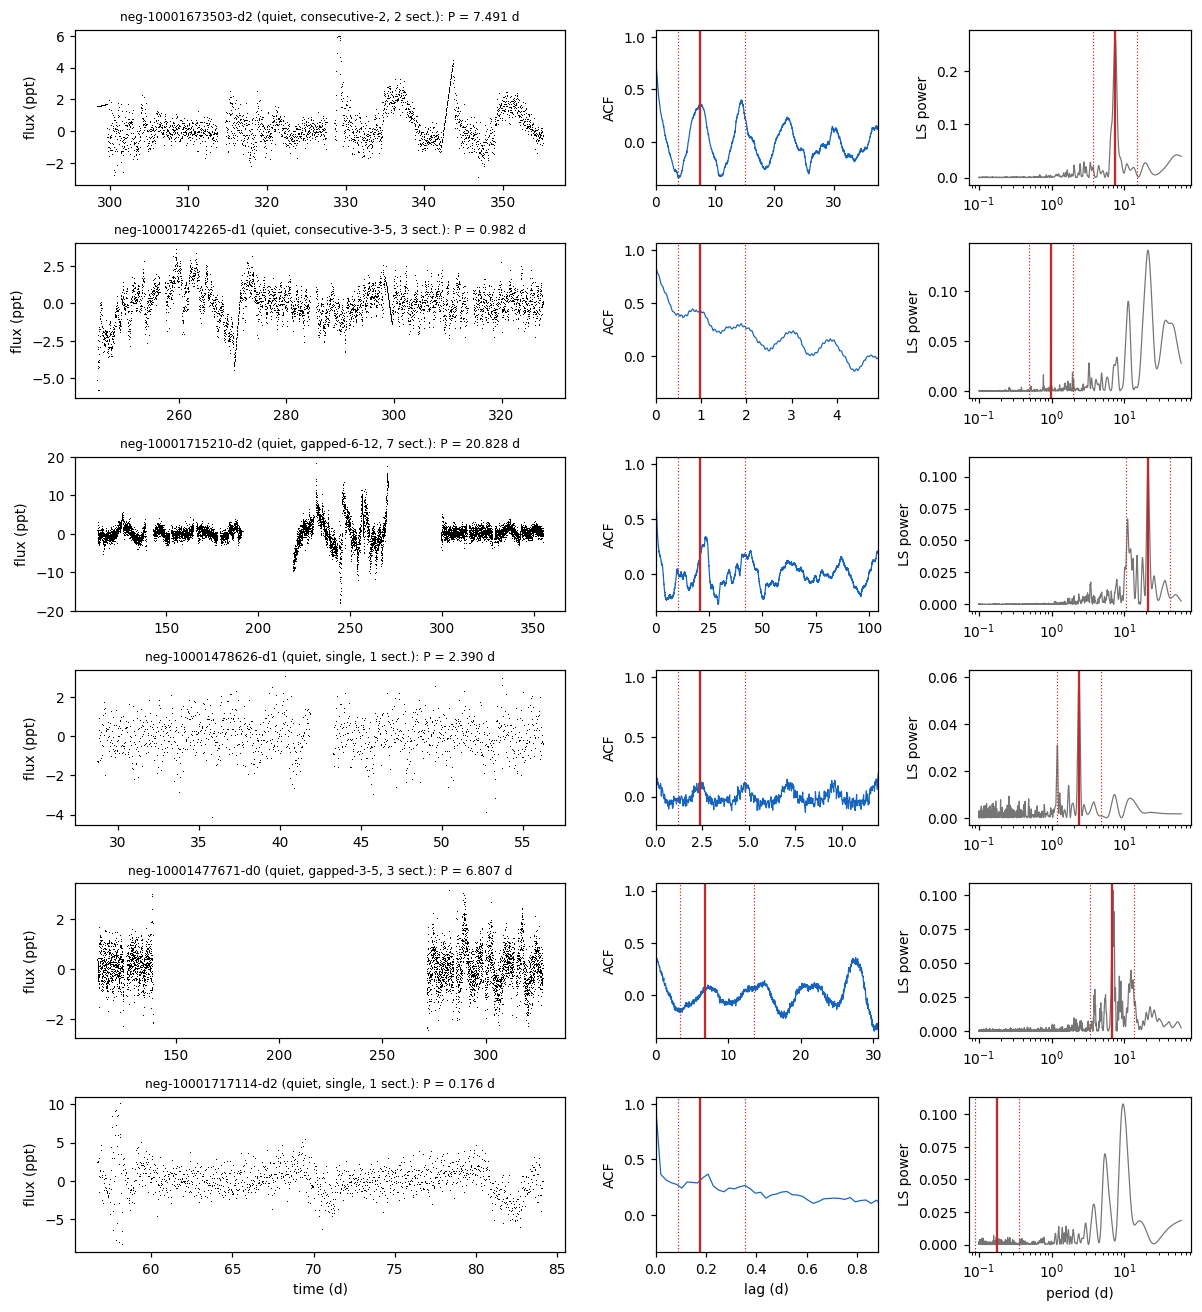

In [5]:
ex = pd.read_csv(D / 'fp_examples.csv'); z = np.load(D / 'fp_examples.npz')
fig, ax = plt.subplots(len(ex), 3, figsize=(11, 2.0 * len(ex)), gridspec_kw=dict(width_ratios=[2.2, 1, 1]))
for k, r in enumerate(ex.itertuples()):
    P = r.final_period
    a = ax[k]
    a[0].plot(z[f't{k}'], z[f'f{k}'] * 1e3, ',', color='k'); a[0].set_ylabel('flux (ppt)')
    a[0].set_title(f'{r.star_id} ({r.source_class}, {r.assigned_coverage_class}, {r.n_sectors} sect.): P = {P:.3f} d', fontsize=8)
    a[1].plot(z[f'lag{k}'], z[f'acf{k}'], color=C['rot'], lw=.8); a[1].set_xlim(0, min(5 * P, z[f'lag{k}'].max()))
    a[2].semilogx(1 / z[f'freq{k}'], z[f'pow{k}'], color=C['grey'], lw=.8)
    for j in (1, 2):
        a[j].axvline(P, color=C['neg']); [a[j].axvline(P * f, color=C['neg'], ls=':', lw=.8) for f in (.5, 2)]
    a[1].set_ylabel('ACF'); a[2].set_ylabel('LS power')
ax[-1][0].set_xlabel('time (d)'); ax[-1][1].set_xlabel('lag (d)'); ax[-1][2].set_xlabel('period (d)')
fig.tight_layout(); fig.savefig(F / 'fp_examples.png', dpi=120); plt.show()

Gate pass rates on fitted candidates: negatives vs rotators (all candidates, and the relevant ones). The gate that most separates them is the one doing the work.

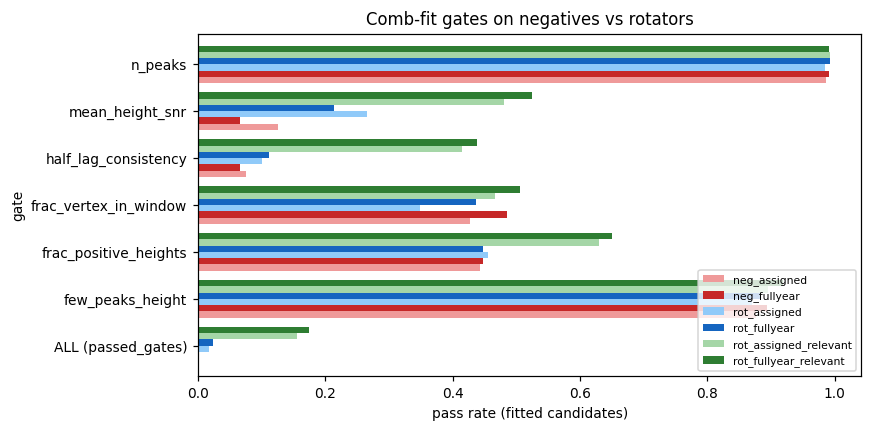

table,neg_assigned,neg_fullyear,rot_assigned,rot_fullyear,rot_assigned_relevant,rot_fullyear_relevant
gate,,,,,,
ALL (passed_gates),0.002,0.000,0.018,0.024,0.156,0.174
few_peaks_height,0.876,0.893,0.870,0.882,0.895,0.919
frac_positive_heights,0.443,0.447,0.456,0.448,0.629,0.651
frac_vertex_in_window,0.427,0.486,0.349,0.436,0.467,0.505
half_lag_consistency,0.075,0.066,0.100,0.112,0.415,0.439
mean_height_snr,0.126,0.066,0.265,0.214,0.480,0.525
n_peaks,0.986,0.992,0.986,0.992,0.992,0.991


In [6]:
gp = pd.read_csv(D / 'gate_pass_rates.csv')
piv = gp.pivot(index='gate', columns='table', values='pass_rate')
order = ['neg_assigned', 'neg_fullyear', 'rot_assigned', 'rot_fullyear', 'rot_assigned_relevant', 'rot_fullyear_relevant']
piv = piv[[c for c in order if c in piv]]
cols = ['#ef9a9a', C['neg'], '#90caf9', C['rot'], '#a5d6a7', C['succ']]
ax = piv.plot.barh(figsize=(8, 4), color=cols[:piv.shape[1]], width=.8)
ax.set_xlabel('pass rate (fitted candidates)'); ax.legend(fontsize=7, loc='lower right'); ax.set_title('Comb-fit gates on negatives vs rotators')
plt.tight_layout(); plt.savefig(F / 'gate_pass_rates.png', dpi=130); plt.show()
piv.round(3)

## 3. Ranker v0 on non-rotators, and with negatives
Top-1 score distributions on dev_medium (assigned): rotators whose top-1 is a success, rotators whose top-1 fails, and non-rotators. Vertical lines: decline thresholds.

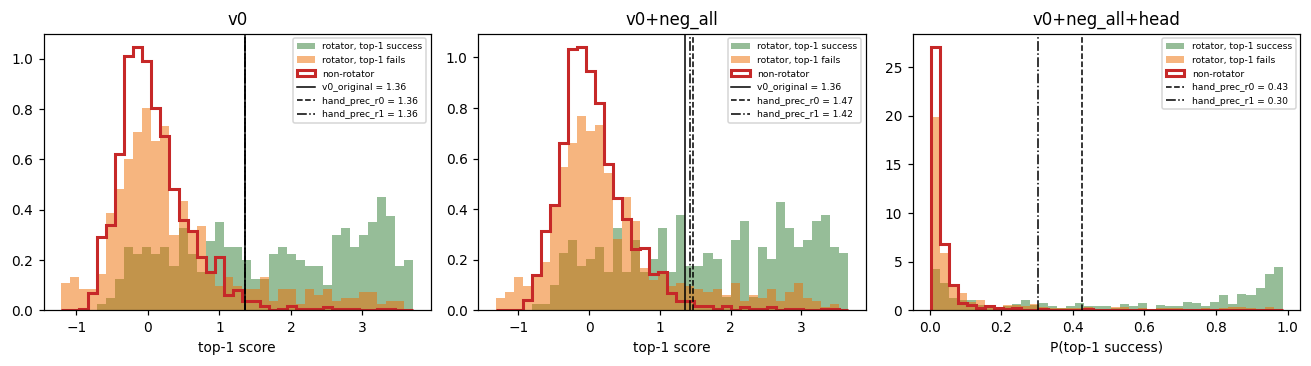

In [7]:
res = json.load(open(RUN / 'results.json'))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), sharey=False)
for a, (name, col) in zip(ax, [('v0', 'top_score'), ('v0+neg_all', 'top_score'), ('v0+neg_all+head', 'top_score')]):
    t = pd.read_csv(RUN / f'{name}_assigned_top1.csv')
    rotm = t.is_rotator.astype(bool); succ = np.isin(t.top_outcome, ev.SUCCESS_OUTCOMES)
    v = t[col].astype(float)
    lo, hi = np.nanpercentile(v, [0.5, 99.5]); b = np.linspace(lo, hi, 40)
    a.hist(v[rotm & succ], b, density=True, alpha=.5, color=C['succ'], label='rotator, top-1 success')
    a.hist(v[rotm & ~succ], b, density=True, alpha=.5, color=C['wrong'], label='rotator, top-1 fails')
    a.hist(v[~rotm], b, density=True, histtype='step', lw=2, color=C['neg'], label='non-rotator')
    th = res['models'][name]['thresholds']
    for tn, ls in [('v0_original', '-'), ('hand_prec_r0', '--'), ('hand_prec_r1', '-.')]:
        if tn in th and np.isfinite(th[tn]) and not (name.endswith('head') and tn == 'v0_original'):
            a.axvline(th[tn], color='k', ls=ls, lw=1, label=f'{tn} = {th[tn]:.2f}')
    a.set_title(name); a.set_xlabel('top-1 score' if 'head' not in name else 'P(top-1 success)'); a.legend(fontsize=6)
fig.tight_layout(); fig.savefig(F / 'ranker_scores.png', dpi=130); plt.show()

Before/after on dev_medium: rotator success / wrong (incl. aliases) / declined, and the non-rotator FP rate, for hand arbitration and each model x threshold.

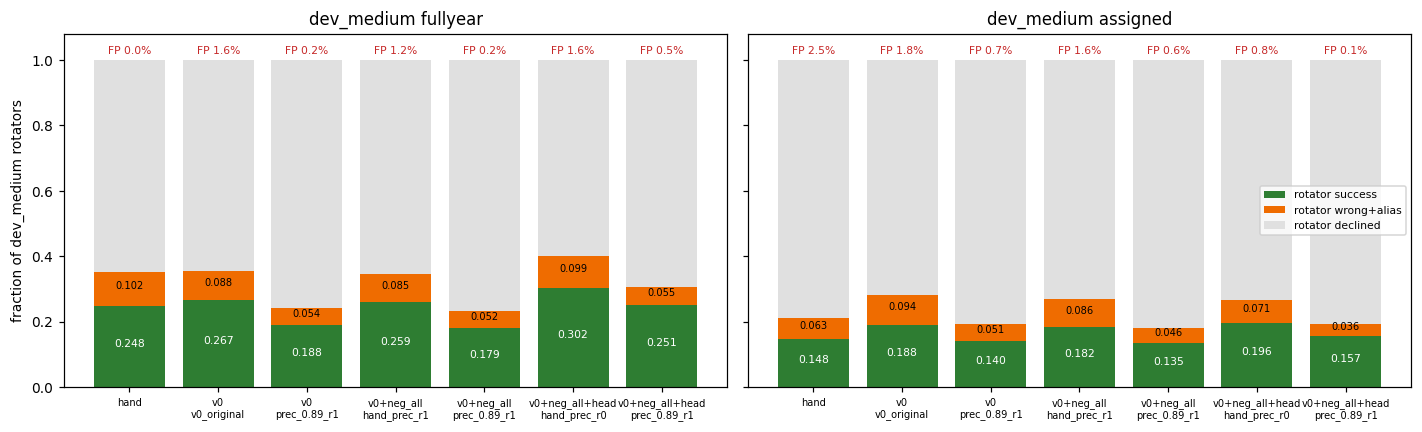

,model,threshold,dev,n_rot,success,alias,wrong,declined,n_neg,neg_fp_rate,precision_r0,precision_r1,thr
0,hand,,fullyear,1000,0.248,0.014,0.088,0.650,434,0.000,0.709,0.709,NaN
1,hand,,assigned,1000,0.148,0.009,0.054,0.789,1302,0.025,0.701,0.628,NaN
2,v0,v0_original,fullyear,1000,0.267,0.008,0.080,0.645,434,0.016,0.752,0.719,1.357
5,v0,prec_0.89_r1,fullyear,1000,0.188,0.005,0.049,0.758,434,0.002,0.777,0.770,2.165
6,v0,v0_original,assigned,1000,0.188,0.007,0.087,0.718,1302,0.018,0.667,0.626,1.357
9,v0,prec_0.89_r1,assigned,1000,0.140,0.004,0.047,0.809,1302,0.007,0.733,0.707,2.165
20,v0+neg_all,hand_prec_r1,fullyear,1000,0.259,0.008,0.077,0.656,434,0.012,0.753,0.729,1.425
21,v0+neg_all,prec_0.89_r1,fullyear,1000,0.179,0.004,0.048,0.769,434,0.002,0.775,0.767,2.204
24,v0+neg_all,hand_prec_r1,assigned,1000,0.182,0.007,0.079,0.732,1302,0.016,0.679,0.641,1.425
25,v0+neg_all,prec_0.89_r1,assigned,1000,0.135,0.002,0.044,0.819,1302,0.006,0.746,0.721,2.204


In [8]:
sm = pd.read_csv(RUN / 'summary.csv')
hand = {k.replace('dev_', ''): v for k, v in res['hand'].items() if k.startswith('dev_')}
rows = [dict(model='hand', threshold='', dev=d, **{k: v for k, v in h.items()}) for d, h in hand.items()]
tab = pd.concat([pd.DataFrame(rows), sm], ignore_index=True)
keep = [('hand', ''), ('v0', 'v0_original'), ('v0', 'prec_0.89_r1'), ('v0+neg_all', 'hand_prec_r1'),
        ('v0+neg_all', 'prec_0.89_r1'), ('v0+neg_all+head', 'hand_prec_r0'), ('v0+neg_all+head', 'prec_0.89_r1')]
tab['key'] = list(zip(tab.model, tab.threshold.fillna('')))
tab = tab[tab.key.isin(keep)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, d in zip(ax, ['fullyear', 'assigned']):
    g = tab[tab.dev == d].set_index('key').reindex(keep)
    lab = [f'{m}\n{t}' for m, t in keep]; x = np.arange(len(keep))
    a.bar(x, g.success, color=C['succ'], label='rotator success')
    a.bar(x, g.wrong + g.alias, bottom=g.success, color=C['wrong'], label='rotator wrong+alias')
    a.bar(x, g.declined, bottom=g.success + g.wrong + g.alias, color='#e0e0e0', label='rotator declined')
    for xi, f, s_, w_ in zip(x, g.neg_fp_rate, g.success, g.wrong + g.alias):
        a.text(xi, 1.02, f'FP {100*f:.1f}%', ha='center', fontsize=7, color=C['neg'])
        a.text(xi, s_ / 2, f'{s_:.3f}', ha='center', fontsize=7, color='w')
        a.text(xi, s_ + w_ / 2, f'{w_:.3f}', ha='center', fontsize=6.5, color='k')
    a.set_ylim(0, 1.08)
    a.set_xticks(x); a.set_xticklabels(lab, fontsize=6.5); a.set_title(f'dev_medium {d}')
ax[0].set_ylabel('fraction of dev_medium rotators'); ax[1].legend(fontsize=7, loc='center right')
fig.tight_layout(); fig.savefig(F / 'ranker_outcomes.png', dpi=130); plt.show()
tab.drop(columns='key').round(3)

Ranker v0 (unchanged) at its own threshold: non-rotator FP rate by coverage class and by top-1 period bin (dev_medium negatives).

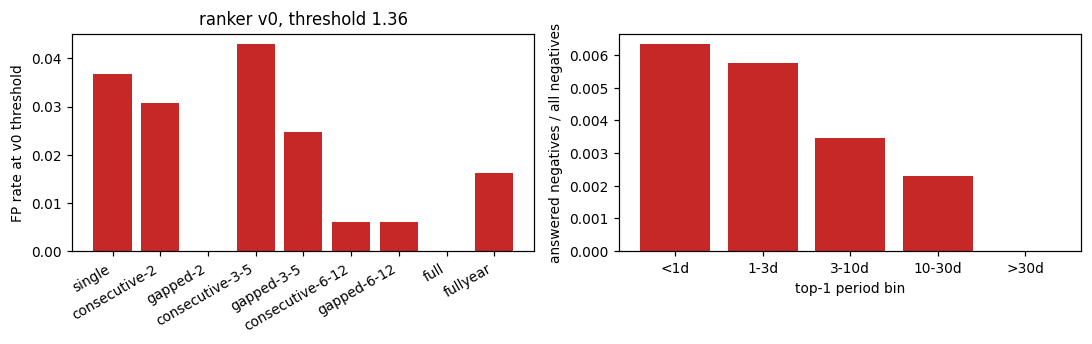

In [9]:
t = pd.read_csv(RUN / 'v0_assigned_top1.csv'); tf = pd.read_csv(RUN / 'v0_fullyear_top1.csv')
thr = res['models']['v0']['thresholds']['v0_original']
n = pd.concat([t, tf]); n = n[~n.is_rotator.astype(bool)].copy()
n['ans'] = n.top_score >= thr
n['pbin'] = [ev.period_bin(p) if np.isfinite(p) else 'none' for p in n.top_period]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
g = n.groupby('coverage').ans.mean().reindex(COV)
ax[0].bar(range(len(COV)), g, color=C['neg']); ax[0].set_xticks(range(len(COV))); ax[0].set_xticklabels(COV, rotation=30, ha='right')
ax[0].set_ylabel('FP rate at v0 threshold'); ax[0].set_title(f'ranker v0, threshold {thr:.2f}')
b = n[n.ans].pbin.value_counts().reindex(ev.PERIOD_BIN_LABELS).fillna(0) / len(n)
ax[1].bar(range(len(b)), b, color=C['neg']); ax[1].set_xticks(range(len(b))); ax[1].set_xticklabels(b.index)
ax[1].set_xlabel('top-1 period bin'); ax[1].set_ylabel('answered negatives / all negatives')
fig.tight_layout(); fig.savefig(F / 'v0_fp_breakdown.png', dpi=130); plt.show()